# Projekt 2A – Raport 4: wyniki na zbiorze testowym i wnioski

Kalina Staniszewska, Agnieszka Michałowska

Notatnik przedstawia **jednorazową** ocenę na zbiorze testowym konfiguracji zamrożonych na walidacji w pliku `final_configs.json` (Raport 3, rozdział 12). Niczego nie trenuje i niczego nie wybiera: czyta wyłącznie pliki zapisane poleceniem `python run_experiments.py --test --potwierdzam-test`.

| Sekcja | Zawartość | Wymaganie |
| --- | --- | --- |
| 8.1 | końcowa tabela porównawcza (metryki i czas obliczeń) | Raport 3A, 4A, szablon sekcja 8 |
| 8.2 | czy LSTM/GRU dają rzeczywistą poprawę względem prostych metod | Raport 3A |
| 8.3 | prognozy dla reprezentatywnego fragmentu zbioru testowego | Raport 2A, 4A |
| 8.4 | błąd w czasie, rozkład reszt, błąd według godziny doby | Raport 4A |
| 8.5 | fragmenty z największymi błędami | Raport 4A |
| 8.6 | najlepsze konfiguracje, wpływ długości okna, walidacja a test | Raport 4A, szablon sekcja 9 |
| 8.7 | weryfikacja hipotez H1–H5 | Raport 1, punkt 12.5 |

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

import ts_data as td
import ts_models as tm
import ts_raport3 as r3
import ts_raport4 as r4

warnings.filterwarnings("ignore")
td.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

ZRODLO = "test"          # "test" po ocenie testowej; "zastepcze" = wyniki z walidacji do sprawdzenia kodu
OUT = tm.OUT
if ZRODLO == "zastepcze":
    TEST = r4.build_standin(OUT, "outputs/zastepcze_z_walidacji")
    FIG = Path("outputs/raport4_zastepcze")
else:
    TEST = OUT
    FIG = Path("outputs/raport4")
res = r4.load_test(TEST)
df, bl = r3.load(OUT)
print("Źródło wyników:", res.zrodlo.iloc[0], "| wiersze:", len(res))
assert ZRODLO == "zastepcze" or not r4.is_standin(res), "wyniki zastępcze nie mogą trafić do raportu"
print("Liczba chwil testowych (zbiór, horyzont):")
display(res.groupby(["key", "h"]).n_test.first().unstack())

Źródło wyników: test | wiersze: 399
Liczba chwil testowych (zbiór, horyzont):


h,1,3,6,12,24
key,,,,,
air,24.0,24.0,NaN,24.0,NaN
household,6190.0,NaN,6175.0,NaN,6121.0
jena,13799.0,NaN,13794.0,NaN,13776.0
metro,10338.0,NaN,10333.0,NaN,10315.0


## 8. Ocena końcowa na zbiorze testowym

### 8.1. Końcowa tabela porównawcza (grupa „A”: identyczne warunki bloku A)

,key,h,model,konfiguracja,MAE,MAE_sd,MSE,RMSE,MAPE,sMAPE,skill,skill_sd,val_MAE,czas_uczenia_s,inferencja_ms,najlepszy
0,jena,1,persistence,,0.686,0.000,0.905,0.951,NaN,NaN,0.000,0.000,0.655,NaN,NaN,False
1,jena,1,seasonal_naive,,2.579,0.000,11.397,3.376,NaN,NaN,-2.758,0.000,2.552,NaN,NaN,False
2,jena,1,linreg,L = 72,0.404,0.000,0.345,0.588,NaN,NaN,0.411,0.000,0.404,NaN,NaN,True
3,jena,1,Dense,L = 72,0.468,0.040,0.421,0.648,NaN,NaN,0.318,0.058,0.472,16.227,43.410,False
4,jena,1,LSTM,L = 72,0.415,0.003,0.353,0.594,NaN,NaN,0.396,0.004,0.411,316.867,116.040,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,air,12,seasonal_naive,,47.583,0.000,2498.667,49.987,10.523,11.167,0.000,0.000,26.375,NaN,NaN,False
68,air,12,linreg,"L = 24, log",11.954,0.000,223.203,14.940,2.607,2.569,0.749,0.000,18.692,NaN,NaN,True
69,air,12,Dense,"L = 24, sdiff",28.726,6.322,1178.552,33.816,6.239,5.986,0.396,0.133,20.996,3.213,44.495,False
70,air,12,LSTM,"L = 24, sdiff",29.892,7.452,1198.423,33.951,6.538,6.274,0.372,0.157,15.045,2.840,62.765,False


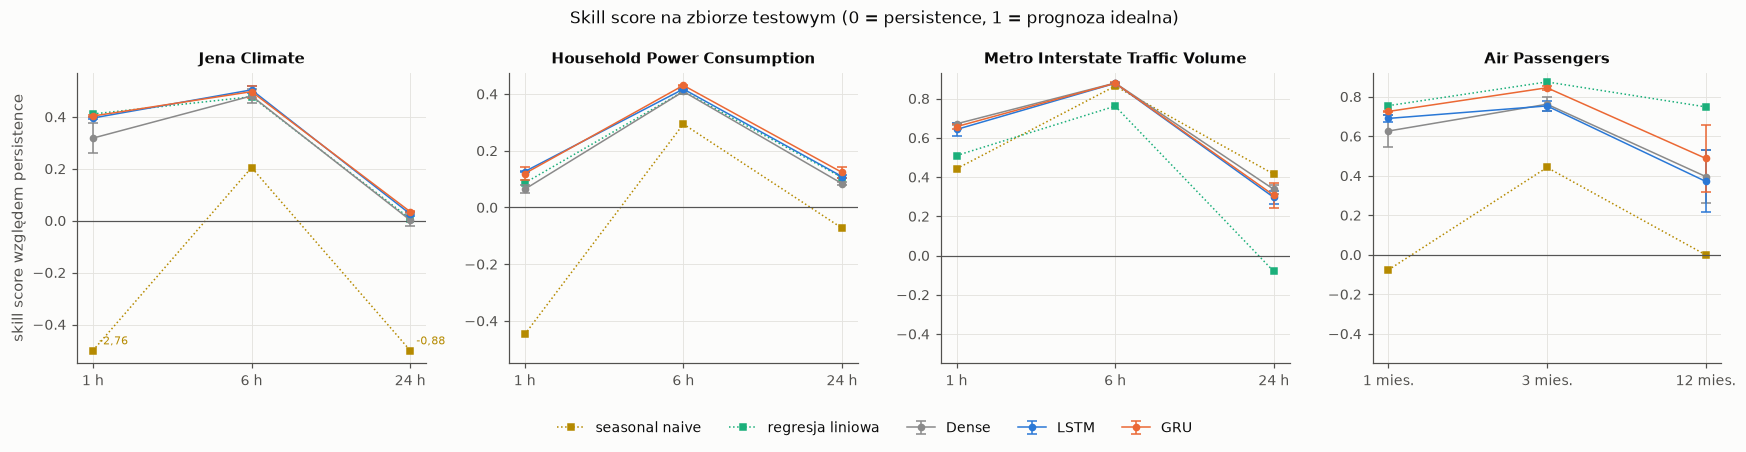

In [2]:
tA = r4.final_table(res, "A", df, bl, FIG)
cols = ["key", "h", "model", "konfiguracja", "MAE", "MAE_sd", "MSE", "RMSE", "MAPE", "sMAPE", "skill", "skill_sd",
        "val_MAE", "czas_uczenia_s", "inferencja_ms", "najlepszy"]
display(tA[cols].round(3))
fig = r4.plot_test_skill(tA, FIG, "A")

**Komentarz.** Nie ma jednego najlepszego modelu dla wszystkich zbiorów. LSTM albo GRU mają najmniejsze MAE w 5 z 12 komórek: Jena Climate przy h = 6 i 24 h oraz Household przy wszystkich horyzontach. Dla Metro przy h = 1 i 6 h najlepsza jest sieć Dense, a przy h = 24 h seasonal naive (328,0 pojazdów/h). Dla Air Passengers przy wszystkich horyzontach najlepsza jest regresja liniowa (MAE 10,7–12,0 tys.), a sieci mają błąd od 12 % do ponad 100 % większy. Seasonal naive dla Metro przy h = 24 h ma najmniejsze MAE, ale większe RMSE niż sieci: zwykle trafia dobrze, ale w nietypowe dni myli się bardzo mocno. Sieci rekurencyjne uczą się od około 20 do ponad 50 razy dłużej niż Dense; GRU prognozuje o około 14 % szybciej niż LSTM.

### 8.2. Czy LSTM i GRU dają rzeczywistą poprawę względem prostych metod?

Najlepszy prosty model (persistence, seasonal naive albo regresja liniowa) wybieramy na **walidacji**, zgodnie z kryterium z Raportu 1. Poprawę uznajemy za wyraźną, gdy różnica MAE jest większa niż odchylenie standardowe między ziarnami sieci.

In [3]:
imp = r4.improvement_table(tA, FIG, "A")
display(imp.round(3))

,key,h,model,MAE,MAE_sd,najlepszy_prosty,MAE_prosty,poprawa_%,wyraźna,vs_Dense_%
0,jena,1,LSTM,0.415,0.003,regresja liniowa,0.404,-2.642,False,11.360
1,jena,1,GRU,0.409,0.002,regresja liniowa,0.404,-1.341,False,12.483
2,jena,6,LSTM,1.608,0.042,regresja liniowa,1.694,5.078,True,4.486
3,jena,6,GRU,1.630,0.073,regresja liniowa,1.694,3.763,False,3.163
4,jena,24,LSTM,2.511,0.020,regresja liniowa,2.558,1.833,True,2.388
5,jena,24,GRU,2.489,0.006,regresja liniowa,2.558,2.709,True,3.259
6,household,1,LSTM,0.342,0.001,regresja liniowa,0.358,4.409,True,6.663
7,household,1,GRU,0.345,0.009,regresja liniowa,0.358,3.633,True,5.905
8,household,6,LSTM,0.468,0.003,regresja liniowa,0.475,1.384,True,1.456
9,household,6,GRU,0.458,0.001,regresja liniowa,0.475,3.584,True,3.655


**Komentarz.** LSTM i GRU dają poprawę wyraźną według przyjętego kryterium (różnica MAE większa niż odchylenie standardowe między ziarnami; nie jest to test statystyczny) w 11 z 24 przypadków, wyłącznie dla zbiorów godzinowych. Dla Jena Climate (h = 6 i 24 h) i Household (h = 1 i 6 h) poprawa wynosi kilka procent, dla Metro przy h = 1 i 6 h 10–30 %. Dla Metro przy h = 24 h sieci są o około 20 % gorsze od seasonal naive, a dla Air Passengers wyraźnie gorsze od regresji liniowej przy wszystkich horyzontach. Dla Metro sieci rekurencyjne są przy tym gorsze od Dense o 0,7–8,8 %, więc poprawa nie wynika z rekurencji.

### 8.3. Prognozy dla reprezentatywnego fragmentu zbioru testowego

Fragment dwóch tygodni wybieramy automatycznie: jest to ten fragment, w którym MAE LSTM jest najbliższe medianie MAE wszystkich fragmentów, czyli fragment typowy, a nie najlepszy. Dla Air Passengers pokazujemy cały okres testowy (1959–1960).

Jena Climate fragment: 2015-11-21 12:00:00 – 2015-12-05 11:00:00
Household Power Consumption fragment: 2010-04-06 03:00:00 – 2010-04-20 02:00:00
Metro Interstate Traffic Volume fragment: 2017-10-22 12:00:00 – 2017-11-05 11:00:00
Air Passengers fragment: 1959-01-01 00:00:00 – 1960-12-01 00:00:00


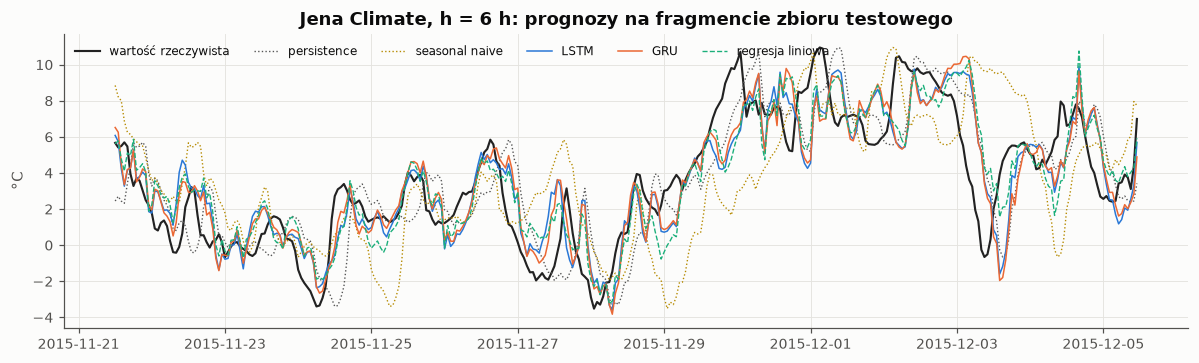

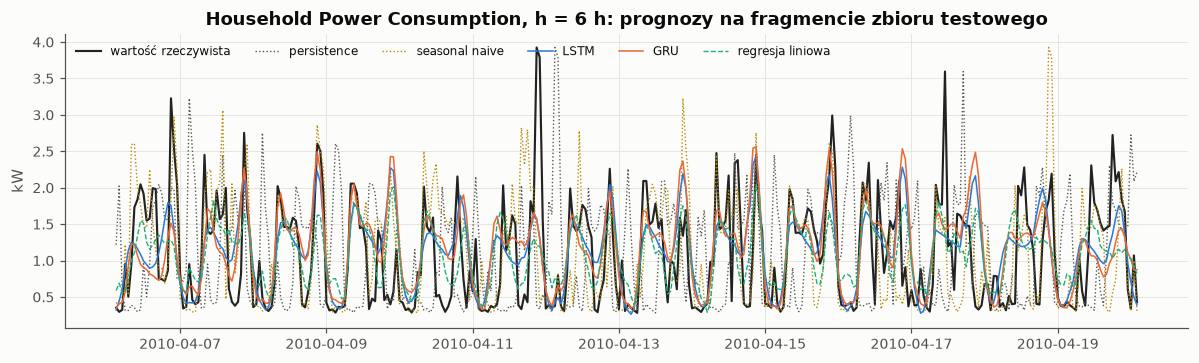

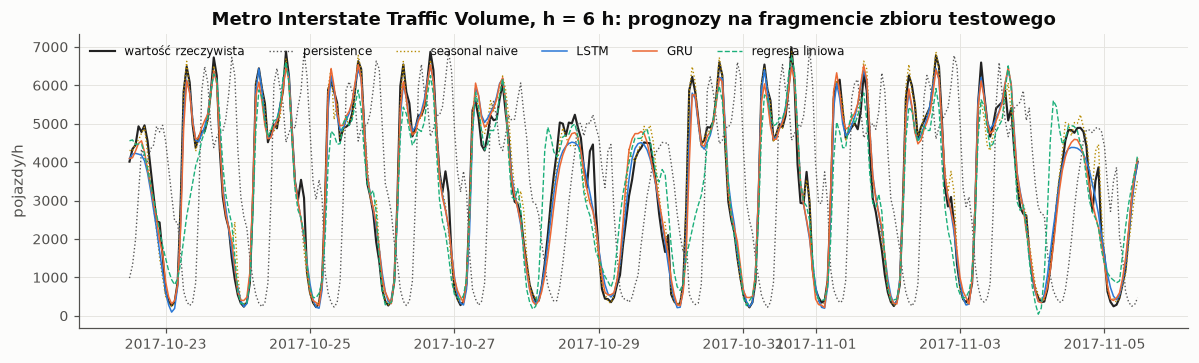

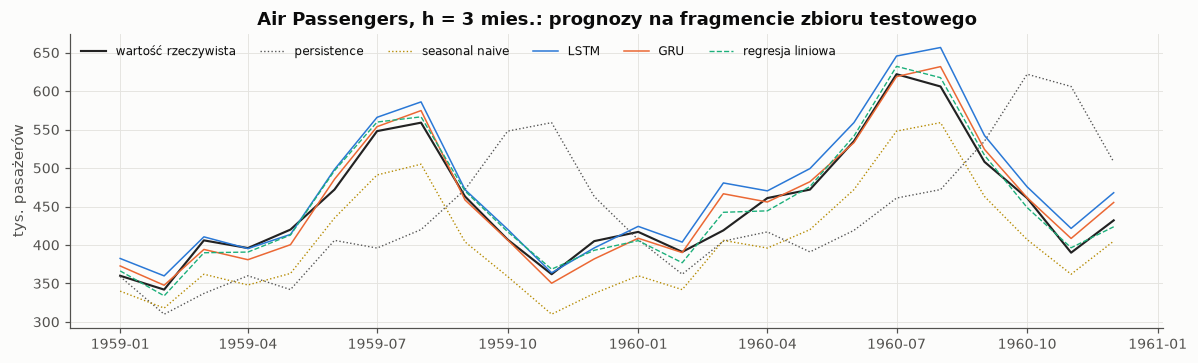

In [4]:
for key in tm.KEYS:
    fig, zakres = r4.plot_test_forecast(res, key, r4.MID_H[key], TEST, "A", FIG)
    print(td.SPECS[key].name, "fragment:", zakres[0], "–", zakres[1])

**Komentarz.** Na typowym fragmencie zbioru testowego sieci zachowują się jak na walidacji: dobrze odtwarzają cykl dobowy (Jena, Household), tygodniowy rytm ruchu (Metro) i sezonowość roczną (Air), ale nie przewidują nagłych zdarzeń. W Jena Climate prognozy reagują z opóźnieniem na ocieplenie 29–30 listopada i ochłodzenie 3 grudnia 2015 r., w Household są gładsze od rzeczywistości i nie odtwarzają krótkich skoków do 3–4 kW. Dla Air Passengers LSTM systematycznie zawyża prognozy w 1960 r., a GRU i regresja liniowa leżą bliżej wartości rzeczywistych.

### 8.4. Błąd w czasie, rozkład reszt i błąd według godziny doby

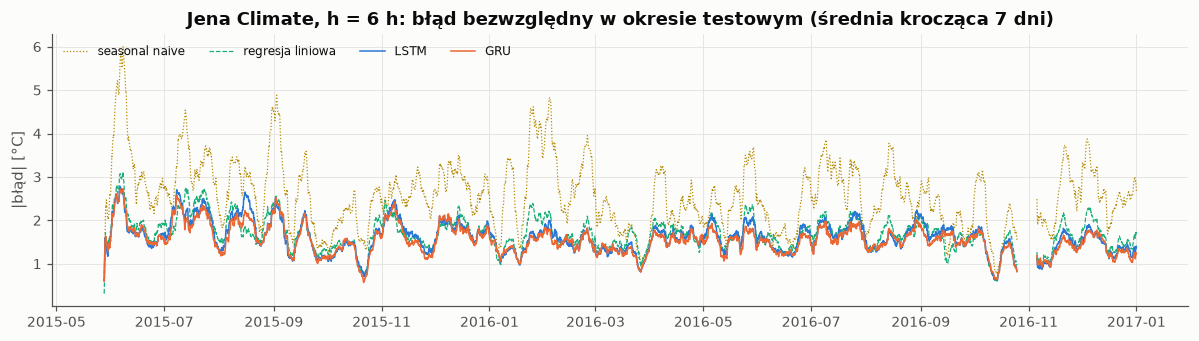

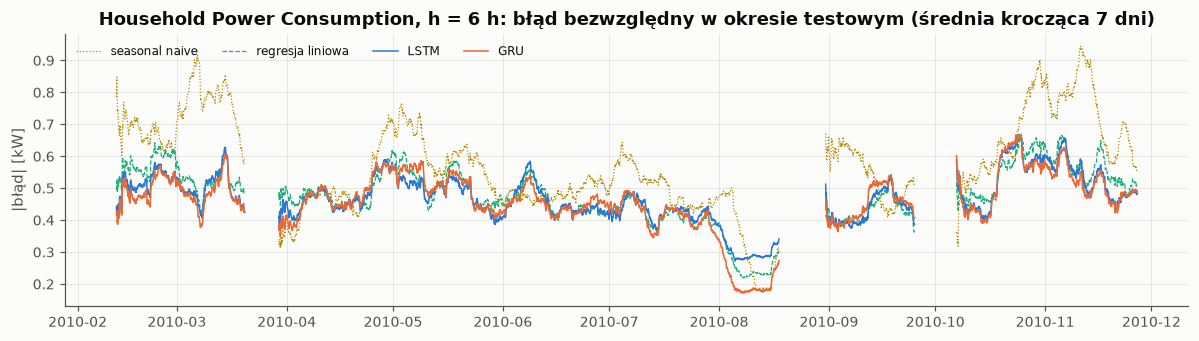

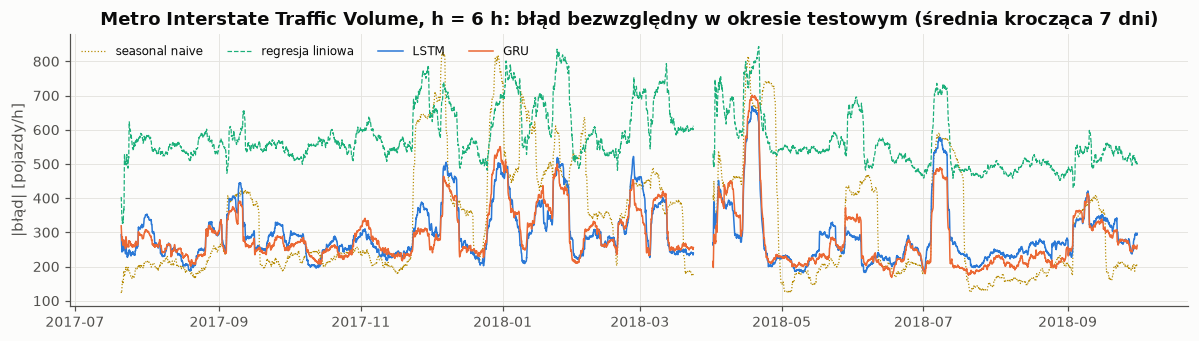

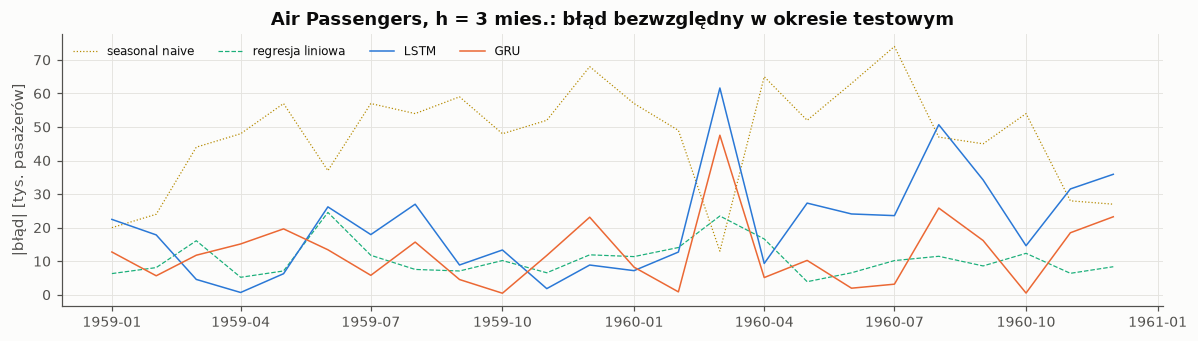

In [5]:
for key in tm.KEYS:
    fig = r4.plot_error_time(res, key, r4.MID_H[key], TEST, "A", FIG)

,key,h,model,średnia reszta,mediana,odch. std.,skośność,P5,P95
0,jena,6,linreg,-0.038,-0.025,2.238,-0.013,-3.761,3.498
1,jena,6,LSTM,-0.176,-0.140,2.103,-0.009,-3.619,3.075
2,jena,6,GRU,-0.050,-0.032,2.028,0.018,-3.384,3.123
3,household,6,linreg,0.036,0.170,0.625,-1.130,-1.091,0.874
4,household,6,LSTM,0.067,0.144,0.614,-0.963,-1.017,0.924
5,household,6,GRU,0.074,0.129,0.614,-0.827,-0.972,0.982
6,metro,6,linreg,-42.441,-12.420,874.432,-0.210,-1311.067,1177.984
7,metro,6,LSTM,-7.673,-5.674,469.242,1.002,-660.986,578.191
8,metro,6,GRU,11.378,17.838,463.505,1.125,-632.252,583.549
9,air,3,linreg,1.391,6.356,12.015,0.093,-15.805,21.726


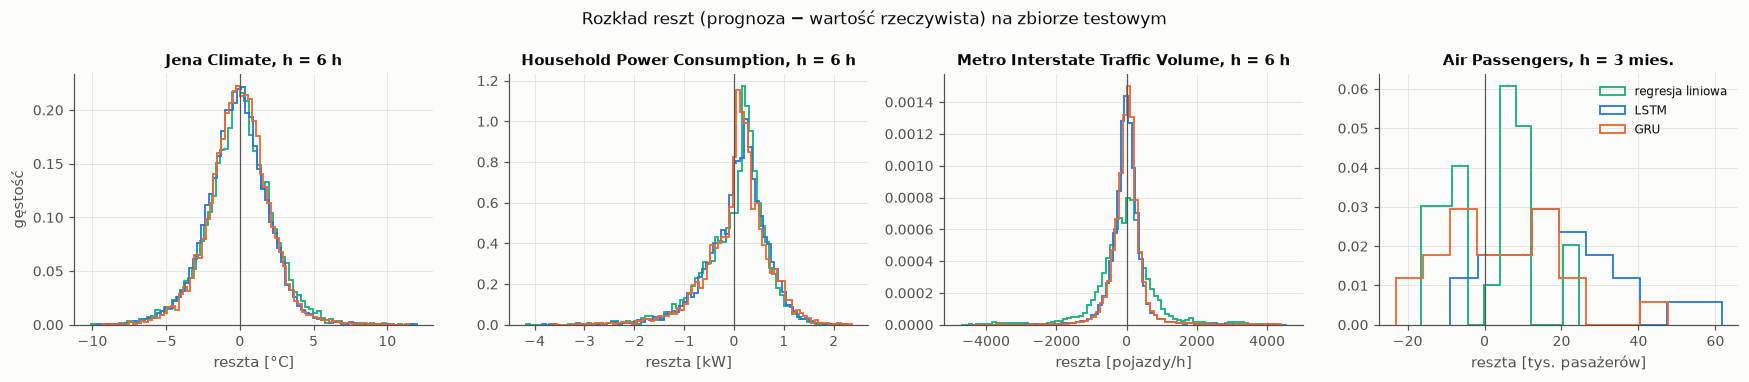

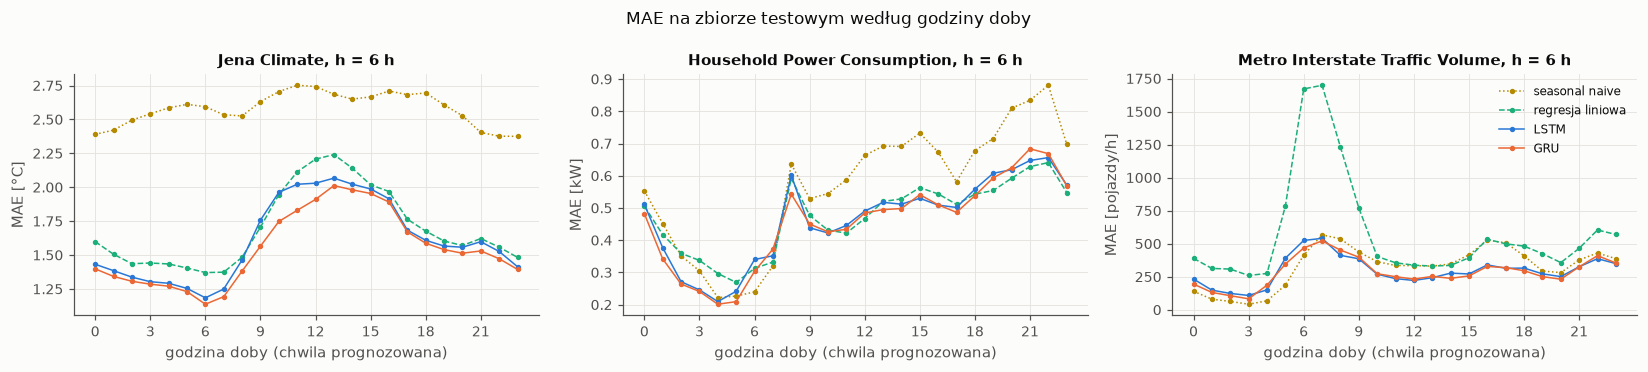

In [6]:
fig, st = r4.plot_residuals(res, TEST, "A", FIG)
display(st.round(3))
fig = r4.plot_error_profile(res, TEST, "A", FIG)

**Komentarz.** Błąd sieci nie jest równomierny w czasie: rośnie latem (Jena), w sezonie grzewczym (Household) i zimą oraz w połowie kwietnia 2018 r. (Metro). W ciągu doby jest największy w godzinach największej zmienności: 10:00–15:00 dla Jena, rano o 8:00 i wieczorem dla Household, w porannym szczycie dla Metro, gdzie regresja liniowa myli się około trzy razy bardziej niż sieci. Rozkład reszt jest symetryczny dla Jena, ma ujemną skośność dla Household (rzadkie, duże zaniżenia przy skokach zużycia) i dodatnią dla Metro (duże zawyżenia, gdy ruch jest nietypowo mały). Systematyczne zawyżanie występuje tylko dla LSTM na Air Passengers (średnia reszta +19,0 tys.).

### 8.5. Fragmenty z największymi błędami

Dla każdego zbioru godzinowego podajemy 10 dni z największym średnim błędem bezwzględnym LSTM (grupa „A”, horyzont środkowy) wraz z błędem pozostałych modeli tego samego dnia, a dla Air Passengers 10 miesięcy.

In [7]:
for key in tm.KEYS:
    print(td.SPECS[key].name)
    display(r4.largest_errors(res, key, r4.MID_H[key], TEST, "A", "LSTM", 10, FIG).round(2))

Jena Climate


,okres,dzień,MAE LSTM,średnia y,MAE GRU,MAE regresja liniowa,MAE seasonal naive,MAE persistence
0,2015-08-14,pt,5.14,25.07,4.43,3.66,5.52,6.57
1,2015-06-01,pn,4.37,13.51,4.44,4.42,8.33,2.67
2,2015-07-07,wt,4.16,23.58,3.51,2.86,4.58,8.13
3,2016-05-23,pn,4.10,15.09,3.65,3.47,7.24,5.10
4,2015-06-02,wt,3.80,16.89,3.64,3.56,7.67,3.73
5,2015-07-04,so,3.74,29.25,3.41,1.96,2.20,6.66
6,2016-08-28,nd,3.64,24.54,3.29,2.31,1.81,8.45
7,2015-08-30,nd,3.48,23.78,3.20,3.00,4.88,6.77
8,2016-05-14,so,3.37,9.95,3.61,2.88,5.66,3.04
9,2016-04-02,so,3.36,7.89,2.73,3.21,4.94,5.95


Household Power Consumption


,okres,dzień,MAE LSTM,średnia y,MAE GRU,MAE regresja liniowa,MAE seasonal naive,MAE persistence
0,2010-10-18,pn,1.13,1.86,1.11,1.05,0.85,1.61
1,2010-03-08,pn,1.02,1.79,0.96,0.93,0.97,1.27
2,2010-11-04,cz,1.00,1.76,0.97,1.07,1.35,1.72
3,2010-04-25,nd,0.94,1.13,0.87,0.84,0.73,0.86
4,2010-05-16,nd,0.88,1.55,0.99,0.89,0.85,1.35
5,2010-05-02,nd,0.86,1.56,0.98,0.96,1.39,0.97
6,2010-02-21,nd,0.84,1.83,0.83,1.00,0.91,1.50
7,2010-10-31,nd,0.82,1.06,0.81,0.84,1.11,0.93
8,2010-11-21,nd,0.80,0.64,0.85,0.69,1.12,0.99
9,2010-05-08,so,0.80,1.10,0.87,0.71,0.66,1.28


Metro Interstate Traffic Volume


,okres,dzień,święto,MAE LSTM,średnia y,MAE GRU,MAE regresja liniowa,MAE seasonal naive,MAE persistence
0,2018-04-14,so,,1811.70,1143.92,1788.94,1992.87,2060.92,1198.38
1,2018-07-04,śr,tak,1368.93,1917.33,1226.39,1224.48,1956.79,1352.83
2,2018-01-22,pn,,1137.62,2126.50,1170.63,1518.93,1020.21,2055.96
3,2018-02-24,so,,1011.25,2401.42,823.15,1067.69,607.04,2290.92
4,2018-03-05,pn,,997.74,2372.88,1028.72,1312.47,1115.29,2220.38
5,2018-04-15,nd,,934.56,1238.33,956.50,744.26,1176.08,788.08
6,2017-12-06,śr,,920.67,3506.04,946.37,852.41,424.00,2286.92
7,2017-09-04,pn,tak,920.49,2395.17,961.54,712.69,1381.08,1949.25
8,2018-09-03,pn,tak,887.42,2323.75,932.10,619.39,1284.08,1882.88
9,2017-12-05,wt,,828.55,2630.62,715.33,977.43,1038.83,1841.00


Air Passengers


,okres,MAE LSTM,średnia y,MAE GRU,MAE regresja liniowa,MAE seasonal naive,MAE persistence
0,1960-03,61.63,419.0,47.56,23.48,13.0,14.0
1,1960-08,50.69,606.0,25.85,11.47,47.0,134.0
2,1960-12,35.91,432.0,23.25,8.36,27.0,76.0
3,1960-09,34.23,508.0,16.17,8.60,45.0,27.0
4,1960-11,31.54,390.0,18.48,6.40,28.0,216.0
5,1960-05,27.33,472.0,10.25,3.90,52.0,81.0
6,1959-08,26.99,559.0,15.70,7.55,54.0,139.0
7,1959-06,26.20,472.0,13.42,24.55,37.0,66.0
8,1960-06,24.09,535.0,1.96,6.55,63.0,116.0
9,1960-07,23.59,622.0,3.16,10.19,74.0,161.0


**Komentarz.** Największe błędy mają konkretne przyczyny: gwałtowne zmiany pogody w Jena Climate (14 sierpnia 2015 r., maksimum 32,8 °C, i przełom maja i czerwca 2015 r.), dni z wysokim zużyciem w Household, opady śniegu (14–15 kwietnia, 22 stycznia, 24 lutego i 5 marca 2018 r.; w danych pogoda opisana jako śnieg przez 13–24 godziny) oraz święta (4 lipca, Labor Day) w Metro, a dla Air Passengers miesiące 1960 r., gdy liczba pasażerów jest wyższa niż w okresie uczenia. W tych dniach błąd wszystkich modeli jest duży. LSTM z dodatkowymi zmiennymi, w tym kalendarzem świąt (grupa „najlepsza”), wyraźnie zmniejsza błąd w święta, ale w dni ze śniegiem niewiele, bo nie zna prognozy pogody.

### 8.6. Najlepsze konfiguracje, wpływ długości okna i porównanie walidacji z testem

In [8]:
tB = r4.final_table(res, "najlepsza", df, bl, FIG)
display(tB[cols].round(3))
display(r4.improvement_table(tB, FIG, "najlepsza").round(3))
display(r4.val_vs_test(tA, FIG, "A").round(3))

,key,h,model,konfiguracja,MAE,MAE_sd,MSE,RMSE,MAPE,sMAPE,skill,skill_sd,val_MAE,czas_uczenia_s,inferencja_ms,najlepszy
0,jena,1,persistence,,0.686,0.000,0.905,0.951,NaN,NaN,0.000,0.000,0.655,NaN,NaN,False
1,jena,1,seasonal_naive,,2.579,0.000,11.397,3.376,NaN,NaN,-2.758,0.000,2.552,NaN,NaN,False
2,jena,1,linreg,"L = 72, + zmienne",0.391,0.000,0.314,0.560,NaN,NaN,0.430,0.000,0.392,NaN,NaN,True
3,jena,1,Dense,L = 72,0.468,0.040,0.421,0.648,NaN,NaN,0.318,0.058,0.472,16.227,43.410,False
4,jena,1,LSTM,"L = 72, + zmienne",0.396,0.006,0.318,0.564,NaN,NaN,0.422,0.009,0.387,584.120,118.960,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,air,12,seasonal_naive,,47.583,0.000,2498.667,49.987,10.523,11.167,0.000,0.000,26.375,NaN,NaN,False
71,air,12,linreg,"L = 12, log",12.196,0.000,234.392,15.310,2.786,2.826,0.744,0.000,16.460,NaN,NaN,True
72,air,12,Dense,"L = 24, sdiff",28.726,6.322,1178.552,33.816,6.239,5.986,0.396,0.133,20.996,3.213,44.495,False
73,air,12,LSTM,"L = 12, sdiff",23.491,0.594,817.072,28.578,5.068,4.891,0.506,0.012,14.160,4.488,53.470,False


,key,h,model,MAE,MAE_sd,najlepszy_prosty,MAE_prosty,poprawa_%,wyraźna,vs_Dense_%
0,jena,1,LSTM,0.396,0.006,regresja liniowa,0.391,-1.315,False,15.254
1,jena,1,GRU,0.407,0.001,regresja liniowa,0.391,-3.974,False,13.031
2,jena,1,TCN,0.392,0.002,regresja liniowa,0.391,-0.165,False,16.216
3,jena,6,LSTM,1.487,0.015,regresja liniowa,1.546,3.842,True,11.702
4,jena,6,GRU,1.554,0.018,regresja liniowa,1.546,-0.506,False,7.710
5,jena,6,TCN,1.541,0.021,regresja liniowa,1.546,0.353,False,8.498
6,jena,24,LSTM,2.379,0.069,regresja liniowa,2.391,0.486,False,7.538
7,jena,24,GRU,2.507,0.021,regresja liniowa,2.391,-4.874,False,2.558
8,jena,24,TCN,2.497,0.021,regresja liniowa,2.391,-4.464,False,2.939
9,household,1,LSTM,0.339,0.001,regresja liniowa,0.360,5.879,True,7.636


,key,h,model,val_MAE,MAE,skill,zmiana_%
0,jena,1,persistence,0.655,0.686,0.000,4.701
1,jena,1,seasonal_naive,2.552,2.579,-2.758,1.049
2,jena,1,linreg,0.404,0.404,0.411,0.101
3,jena,1,Dense,0.472,0.468,0.318,-0.788
4,jena,1,LSTM,0.411,0.415,0.396,0.907
...,...,...,...,...,...,...,...
67,air,12,seasonal_naive,26.375,47.583,0.000,80.411
68,air,12,linreg,18.692,11.954,0.749,-36.047
69,air,12,Dense,20.996,28.726,0.396,36.813
70,air,12,LSTM,15.045,29.892,0.372,98.676


**Komentarz.** LSTM z dodatkowymi zmiennymi jest najlepszy w sześciu komórkach (Jena h = 6 i 24 h, Household h = 1 h, Metro wszystkie horyzonty). Dla Metro przy h = 24 h MAE spada z 394,5 do 278,0 pojazdów/h i LSTM pokonuje seasonal naive (328,0); w poszczególnych dniach największa poprawa dotyczy świąt, a nie dni ze śniegiem; wariant wielowymiarowy dodaje jednak naraz kilka zmiennych, więc bez osobnego eksperymentu nie da się dokładnie wyodrębnić wpływu samego kalendarza. Okno 168 h poprawia GRU dla Metro przy h = 24 h o 14,9 %, a dla Jena przy h = 6 h o 4,7 %. TCN dla Jena jest lepsza od LSTM i GRU w tych samych warunkach przy h = 1 i 6 h. Dla zbiorów godzinowych najlepszy model na walidacji jest najlepszy także na teście we wszystkich dziewięciu komórkach, a zmiany MAE między walidacją a testem są podobne dla wszystkich modeli (Jena +0–5 %, Household −3,5 do −5,3 %, Metro sieci −1 do −14 %). Dla Air Passengers walidacja na 24 miesiącach była dla sieci zbyt optymistyczna: na teście ich błąd wzrósł o 6–99 % (poza GRU przy h = 3).

### 8.7. Weryfikacja hipotez H1–H5

Kryteria pochodzą z Raportu 1 (punkt 12.5). H1, H3 i H5 sprawdzamy na zbiorze testowym (grupa „A”). H2 i H4 zgodnie z Raportem 1 oceniane są na walidacji (bloki B i C), bo na zbiorze testowym ocenione są tylko konfiguracje zamrożone.

In [9]:
H = r4.hypotheses(res, df, bl, FIG)
for k in ("H1", "H2", "H3", "H4", "H5"):
    print(k, {a: b for a, b in H[k].items() if a != "tabela"})
    display(H[k]["tabela"].round(3))

H1 {'potwierdzona': False, 'opis': 'warunek spełniony dla obu sieci w 0 z 3 zbiorów godzinowych'}


,key,model,skill_h1,skill_h6,skill_h24,h6>h1,h24>h1,warunek
0,jena,LSTM,0.396,0.504,0.026,True,False,False
1,jena,GRU,0.403,0.497,0.035,True,False,False
2,household,LSTM,0.127,0.418,0.109,True,False,False
3,household,GRU,0.120,0.431,0.124,True,False,False
4,metro,LSTM,0.643,0.878,0.296,True,False,False
5,metro,GRU,0.657,0.879,0.307,True,False,False


H2 {'spełnione': 8, 'komorki': 18}


,key,h,model,MAE_krótkie,MAE_dłuższe,warunek
0,jena,1,GRU,0.426,"24: 0.410, 72: 0.407, 168: 0.404",True
1,jena,1,LSTM,0.428,"24: 0.411, 72: 0.411, 168: 0.413",True
2,jena,6,GRU,1.978,"24: 1.611, 72: 1.621, 168: 1.530",True
3,jena,6,LSTM,1.986,"24: 1.620, 72: 1.595, 168: 1.570",True
4,jena,24,GRU,2.484,"24: 2.450, 72: 2.426, 168: 2.415",True
5,jena,24,LSTM,2.491,"24: 2.444, 72: 2.433, 168: 2.406",True
6,metro,1,GRU,219.939,168: 220.511,False
7,metro,1,LSTM,233.140,168: 225.283,False
8,metro,6,GRU,341.542,168: 360.536,False
9,metro,6,LSTM,333.921,168: 317.121,False


H3 {'potwierdzona_dla_h': {1: True, 3: True, 12: True}}


,h,model,MAE,MAE_sd,prosty,MAE_prosty,wyraźnie_lepsza
0,1,LSTM,13.692,0.829,regresja liniowa,10.838,False
1,1,GRU,12.132,0.171,regresja liniowa,10.838,False
2,3,LSTM,21.019,2.184,regresja liniowa,10.661,False
3,3,GRU,13.183,0.880,regresja liniowa,10.661,False
4,12,LSTM,29.892,7.452,regresja liniowa,11.954,False
5,12,GRU,24.345,8.100,regresja liniowa,11.954,False


H4 {'potwierdzona_dla': {'household': False, 'jena': True, 'metro': True}}


,key,h,LSTM_uni,LSTM_multi,zmiana_LSTM_%,wszystkie_ziarna_lepsze
0,jena,1,0.411,0.387,-5.906,True
1,jena,6,1.595,1.461,-8.418,True
2,jena,24,2.433,2.348,-3.496,True
3,household,1,0.358,0.349,-2.271,True
4,household,6,0.486,0.517,6.522,False
5,household,24,0.493,0.525,6.290,False
6,metro,1,233.140,210.051,-9.903,True
7,metro,6,333.921,301.596,-9.680,True
8,metro,24,401.515,305.880,-23.819,True


H5 {'komorki_porownywalne': 7, 'komorki': 12, 'czas_LSTM_s': 84.5416091954023, 'czas_GRU_s': 90.58057471264368, 'potwierdzona': False}


,key,h,MAE_LSTM,MAE_GRU,różnica,rozrzut,porównywalne,czas_LSTM_s,czas_GRU_s
0,jena,1,0.415,0.409,-0.005,0.003,False,316.867,594.623
1,jena,6,1.608,1.630,0.022,0.073,True,690.670,440.740
2,jena,24,2.511,2.489,-0.022,0.020,False,327.563,308.507
3,household,1,0.342,0.345,0.003,0.009,True,193.923,204.980
4,household,6,0.468,0.458,-0.010,0.003,False,92.167,157.167
5,household,24,0.472,0.464,-0.008,0.010,True,85.947,122.507
6,metro,1,210.613,202.027,-8.586,18.118,True,215.887,240.457
7,metro,6,293.766,292.728,-1.038,14.904,True,267.350,258.380
8,metro,24,394.450,388.330,-6.121,35.171,True,173.097,201.140
9,air,1,13.692,12.132,-1.560,0.829,False,3.240,3.652


**Komentarz.** H1 niepotwierdzona: skill score przy h = 6 h jest wyższy niż przy h = 1 h we wszystkich zbiorach, ale przy h = 24 h niższy, bo persistence dla h = 24 h powtarza wartość sprzed doby o tej samej godzinie, czyli korzysta z cyklu dobowego. Nie jest to ten sam model co seasonal naive, który przy h = 24 h używa okresu tygodniowego (dla Metro jest on lepszy od persistence: 328,0 wobec 560,7 pojazdów/h). H2 potwierdzona dla Jena (6 z 6), częściowo dla Metro (tylko h = 24 h), niepotwierdzona dla Air (łącznie 8 z 18 komórek). H3 potwierdzona: na Air Passengers żadna sieć nie pokonuje regresji liniowej. H4 potwierdzona dla Jena i Metro, niepotwierdzona dla Household (poprawa tylko przy h = 1 h). H5 niepotwierdzona: wyniki GRU i LSTM są porównywalne w 7 z 12 komórek, ale średni czas uczenia GRU ze wszystkich 87 treningów bloku A (90,6 s; przeważają krótkie treningi Air Passengers) jest dłuższy niż LSTM (84,5 s); GRU uczy się dłużej także na każdym zbiorze osobno, bo GRU uczy się średnio przez więcej epok (51,1 wobec 46,5), mimo nieco krótszej epoki.

## 9. Wnioski końcowe

1. LSTM i GRU dają poprawę względem najlepszej prostej metody wyraźną według przyjętego kryterium w 11 z 24 przypadków, wyłącznie dla długich szeregów godzinowych; dla Air Passengers lepsza jest regresja liniowa.
2. Regresja liniowa i seasonal naive są wymagającymi punktami odniesienia: bez nich przewaga sieci wyglądałaby na dużo większą.
3. Rekurencja nie zawsze jest potrzebna: dla Metro Dense dorównuje LSTM i GRU przy wielokrotnie krótszym uczeniu, a dla Jena TCN dorównuje sieciom rekurencyjnym lub je przewyższa.
4. Największy zysk dają dobre wejścia: zmienne pogodowe i kalendarzowe zmniejszyły błąd LSTM dla Metro przy h = 24 h o 29,5 % (największa poprawa w poszczególnych dniach dotyczyła świąt), a okno tygodniowe poprawiło GRU o 14,9 %.
5. LSTM i GRU dają podobne wyniki; GRU prognozuje szybciej, ale nie uczy się krócej.
6. Największe błędy wynikają ze zdarzeń nietypowych (zmiany pogody, śnieżyce, święta, wysoki poziom szeregu), których modele uczone na samej historii nie mogą przewidzieć.
7. Dla zbiorów godzinowych walidacja dobrze przewiduje wynik testowy; dla Air Passengers 24 miesiące walidacji to za mało.